In [1]:
!git clone https://github.com/hanbanthan/landmark-classification
%cd /content/landmark-classification

Cloning into 'landmark-classification'...
remote: Enumerating objects: 51, done.
remote: Counting objects: 100% (51/51), done.
remote: Compressing objects: 100% (36/36), done.
remote: Total 51 (delta 23), reused 40 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (51/51), 906.90 KiB | 41.22 MiB/s, done.
Resolving deltas: 100% (23/23), done.
/content/landmark-classification


In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## Setting up


In [3]:
!pip install -r requirements.txt | grep -v "already satisfied"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 199.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 163.5 MB/s  0:00:00
  Attempting uninstall: tqdm
    Found existing installation: tqdm 4.67.3
    Uninstalling tqdm-4.67.3:
      Successfully uninstalled tqdm-4.67.3
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 5.0.0.93
    Uninstalling opencv-python-headless-5.0.0.93:
      Successfully uninstalled opencv-python-headless-5.0.0.93
  Attempting uninstall: pytest
    Found existing installation: pytest 8.4.2
    Uninstalling pytest-8.4.2:
      Successfully uninstalled pytest-8.4.2

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
prophet 1.5.0 requires tqdm>=4.63.2, but you have tqdm 4.63.0 which is incompatible.
datasets 4.8.5 requires tqdm>=4.66.3, but you have tqdm 4.63.0 

In [4]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))
print("CUDA available:", torch.cuda.is_available())

CUDA available: True
NVIDIA L4
CUDA available: True


In [1]:
from src.helpers import setup_env

setup_env()



KeyboardInterrupt: 

## Create Transfer Learning Architecture

In [6]:
!pytest -vv src/transfer.py

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-7.1.1, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/landmark-classification
plugins: platformdirs-4.14.3, anyio-4.16.0, langsmith-0.14.17, typeguard-4.6.0
collected 1 item                                                               

src/transfer.py::test_get_model_transfer_learning PASSED                 [100%]

=============================== warnings summary ===============================
src/transfer.py::test_get_model_transfer_learning
  /usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
    warnings.warn(

src/transfer.py::test_get_model_transfer_learning
  /usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum o

## Train, validation, and test
  

In [13]:
batch_size = 64  # size of the minibatch for stochastic gradient descent (or Adam)
valid_size = 0.2  # fraction of the training data to reserve for validation
num_epochs = 50  # number of epochs for training
num_classes = 50  # number of classes. Do not change this
learning_rate = 0.001  # Learning rate for SGD (or Adam)
opt = 'adam'      # optimizer. 'sgd' or 'adam'
weight_decay = 0.0005 # regularization. Increase this to combat overfitting

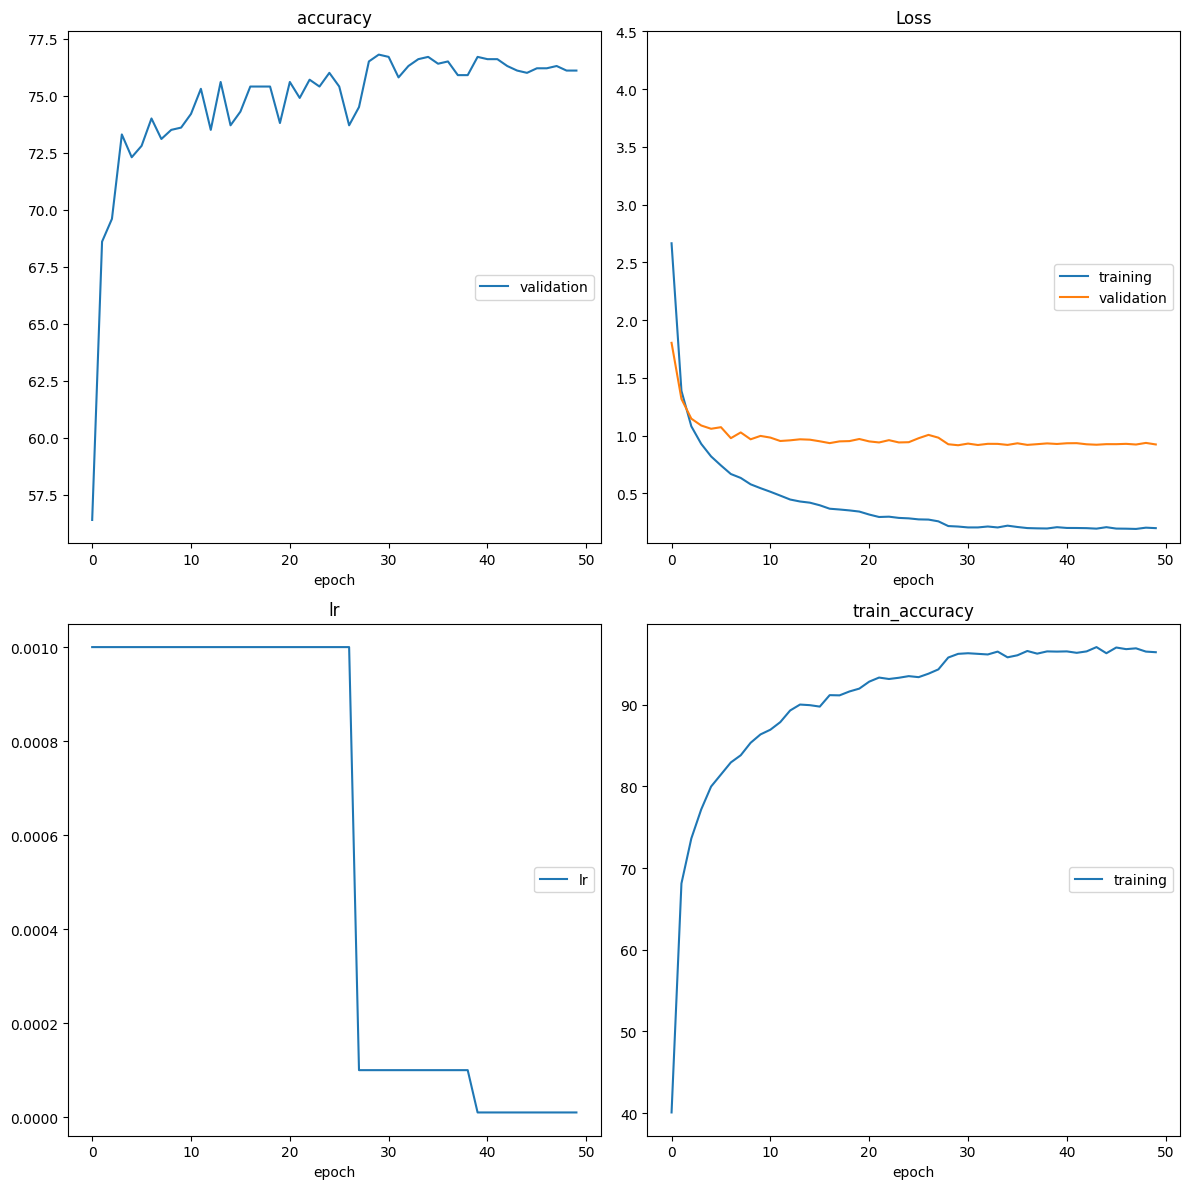

In [14]:
from src.data import get_data_loaders
from src.optimization import get_optimizer, get_loss
from src.train import optimize
from src.transfer import get_model_transfer_learning

model_transfer = get_model_transfer_learning(model_name="resnet50", n_classes=num_classes)

data_loaders = get_data_loaders(batch_size, valid_size)
optimizer = get_optimizer(
    model_transfer,
    learning_rate=learning_rate,
    optimizer=opt,
    weight_decay=weight_decay,
)

loss = get_loss()

optimize(
    data_loaders,
    model_transfer,
    optimizer,
    loss,
    n_epochs=num_epochs,
    save_path="checkpoints/model_transfer.pt",
    interactive_tracking=True,
)

Question: Outline the steps you took to get to your final CNN architecture and your reasoning at each step. Describe why you think the architecture is suitable for the current problem.

Answer:
I decided to use ResNet50 for the base model, since it performs fairly well on ImageNet and is not too large of a model. Also, since ResNet50 was trained on ImageNet task, it is good model to use for this landmark classification task, since both ImageNet and this landmark use images of natural sences

## Test the model


In [15]:
import torch
from src.train import one_epoch_test
from src.transfer import get_model_transfer_learning

model_transfer = get_model_transfer_learning(model_name="resnet50", n_classes=num_classes)
model_transfer.load_state_dict(torch.load("checkpoints/model_transfer.pt"))
one_epoch_test(data_loaders["test"], model_transfer, loss)

Testing: 100%|██████████████████████████████████| 20/20 [00:03<00:00,  6.25it/s]

Test Loss: 0.820664


Test Accuracy: 78% (986/1250)


0.8206638529896735

## Export using torchscript

In [18]:
from src.predictor import Predictor
from src.helpers import compute_mean_and_std

class_names = data_loaders["train"].dataset.classes

model_transfer = model_transfer.cpu()

model_transfer.load_state_dict(
    torch.load("checkpoints/model_transfer.pt", map_location="cpu")
)

mean, std = compute_mean_and_std()
predictor = Predictor(model_transfer, class_names, mean, std).cpu()

scripted_predictor = torch.jit.script(predictor)
scripted_predictor.save("checkpoints/transfer_exported.pt")


Reusing cached mean and std


100%|███████████████████████████████████████| 1250/1250 [00:52<00:00, 23.81it/s]


Accuracy: 0.7904


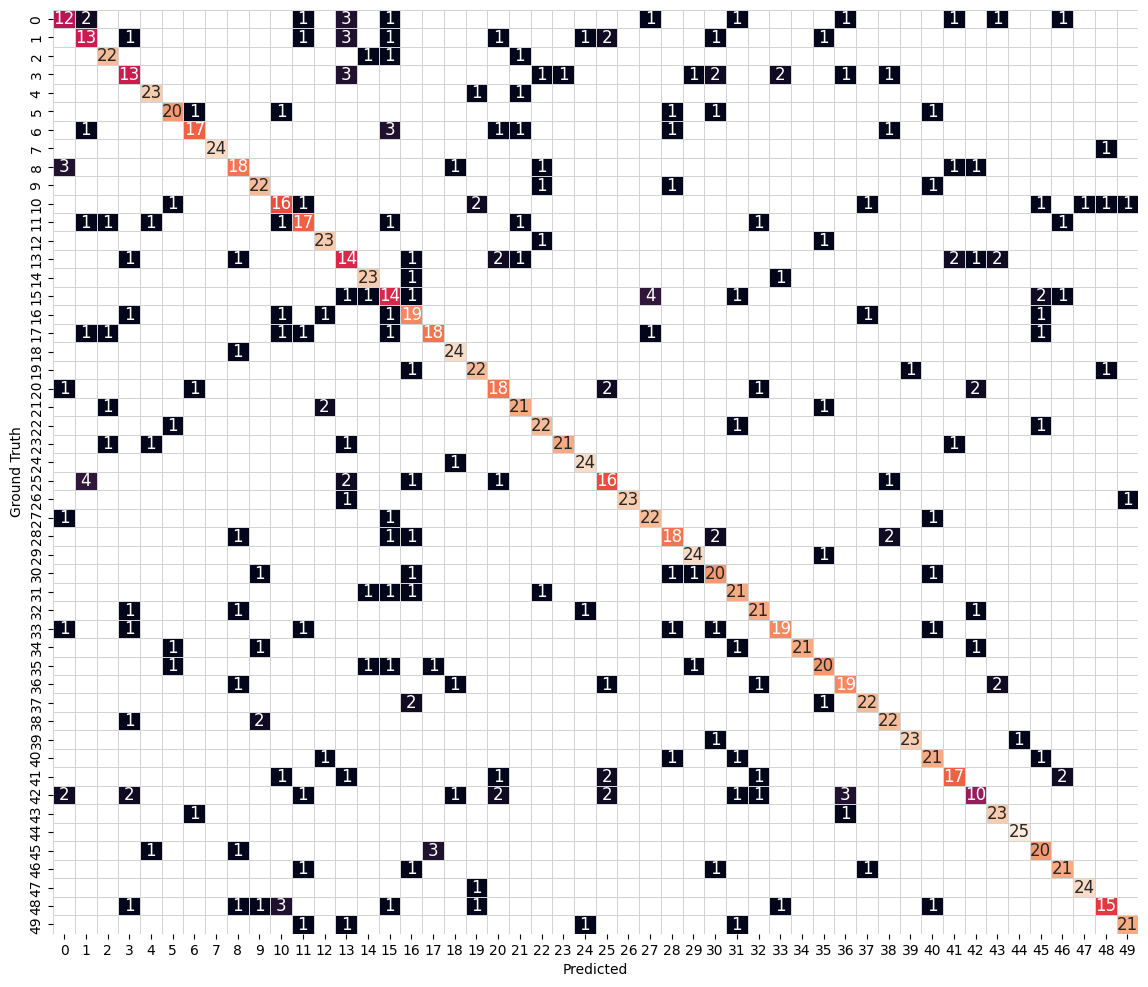

In [19]:
import torch
from src.predictor import predictor_test
from src.helpers import plot_confusion_matrix

model_reloaded = torch.jit.load("checkpoints/transfer_exported.pt")

pred, truth = predictor_test(data_loaders["test"], model_reloaded)
plot_confusion_matrix(pred, truth)